## Step 3: Building a prediction model

In [86]:
import pandas as pd
df = pd.read_csv('cleaned_dataset.csv')

In [87]:
#Split the data into X and y
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["month"] = df["Date"].dt.month

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["month"] = df["Date"].dt.month

#Split the data into X and y
X = df.drop(["Retard moyen de tous les trains à l\'arrivée", "Date", "Service", "Gare de départ", "Gare d'arrivée"], axis=1)
X["month"] = df["month"]
y = df["Retard moyen de tous les trains à l\'arrivée"]

X.shape, y.shape

((10664, 19), (10664,))

In [88]:
from sklearn.model_selection import train_test_split
#Split the data into training and testing

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#print shape of training and testing
print("Training set shape: ", X_train.shape, y_train.shape)
print("Testing set shape: ", X_test.shape, y_test.shape)

Training set shape:  (8531, 19) (8531,)
Testing set shape:  (2133, 19) (2133,)


In [89]:
from sklearn.linear_model import LinearRegression

#Create a linear regression model

lr = LinearRegression()

In [90]:
#Model training

lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [91]:
#Predict on testing set

y_predict = lr.predict(X_test)

#y_predict are predicted values of the target variable based on the columns

In [92]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

#Evaluate the performance of the model
   
r2 = r2_score(y_test, y_predict) #Variance of the target explained by the independent variables (features)  / Higher value is better
mse = mean_squared_error(y_test, y_predict) #Average squared distance between the predicted and the actual values  / Lower value is better
mae = mean_absolute_error(y_test, y_predict) #Average absolute distance between the predicted and the actual values  / Lower value is better
intercept = lr.intercept_  #Starting point of the regression line on the y axis
                        #If positive number, target increases as features increase and reverse


print("R2 score: ", r2)
print("Mean Squared Error: ", mse)
print("Mean Absolute Error: ", mae)
print("Intercept: ", intercept)

R2 score:  0.6730110817245001
Mean Squared Error:  5.257294880310315
Mean Absolute Error:  1.490371052335494
Intercept:  0.6701238494244572


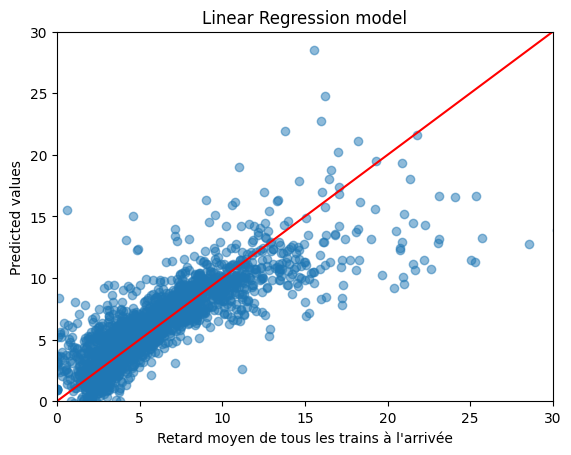

In [93]:
import matplotlib.pyplot as plt

#Compare the model to the actual values, if it is good then it should be close to match the diagonal line

plt.scatter(y_test, y_predict, alpha=0.5)
plt.xlim(0,30)
plt.ylim(0,30)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color = "red")
plt.xlabel("Retard moyen de tous les trains à l'arrivée")
plt.ylabel("Predicted values")
plt.title("Linear Regression model")
plt.show()

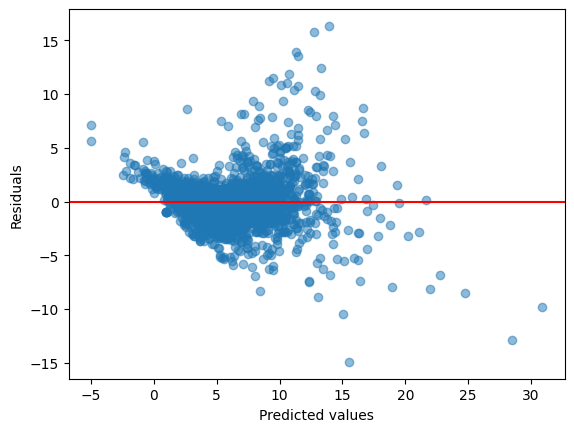

In [94]:
plt.scatter(y_predict, y_test - y_predict, alpha=0.5)
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.axhline(color="red")
plt.show()

# Interpretation

The model capture the general relationship, error variances increases as the predicted values does. 
This graphic just like the previous one show that the bigger the delays, the less accurate the predictions becomes. There is a possibility of constant variation.

## Data leak fix

In [95]:
df = pd.read_csv('cleaned_dataset.csv')

In [96]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["month"] = df["Date"].dt.month

#Split the data into X and y
X = df.drop(["Retard moyen de tous les trains à l\'arrivée", "Date", "Service", "Gare de départ", "Gare d'arrivée", "Nombre trains en retard > 15min", "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)", "Nombre trains en retard > 30min", "Nombre trains en retard > 60min"], axis=1)
X["month"] = df["month"]
y = df["Retard moyen de tous les trains à l\'arrivée"]

X.shape, y.shape

((10664, 15), (10664,))

In [97]:
from sklearn.model_selection import train_test_split
#Split the data into training and testing

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#print shape of training and testing
print("Training set shape: ", X_train.shape, y_train.shape)
print("Testing set shape: ", X_test.shape, y_test.shape)

Training set shape:  (8531, 15) (8531,)
Testing set shape:  (2133, 15) (2133,)


In [98]:
from sklearn.linear_model import LinearRegression

#Create a linear regression model

lr = LinearRegression()

In [99]:
#Model training

lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [100]:
#Predict on testing set

y_predict = lr.predict(X_test)

#y_predict are predicted values of the target variable based on the columns

In [101]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

#Evaluate the performance of the model

r2 = r2_score(y_test, y_predict) #Variance of the target explained by the independent variables (features)  / Higher value is better
mse = mean_squared_error(y_test, y_predict) #Average squared distance between the predicted and the actual values  / Lower value is better
mae = mean_absolute_error(y_test, y_predict) #Average absolute distance between the predicted and the actual values  / Lower value is better
intercept = lr.intercept_  #Starting point of the regression line on the y axis
                        #If positive number, target increases as features increase and reverse


print("R2 score: ", r2)
print("Mean Squared Error: ", mse)
print("Mean Absolute Error: ", mae)
print("Intercept: ", intercept)

R2 score:  0.6442488726235536
Mean Squared Error:  5.7197307801270165
Mean Absolute Error:  1.5542413466777414
Intercept:  -0.4088440270554168


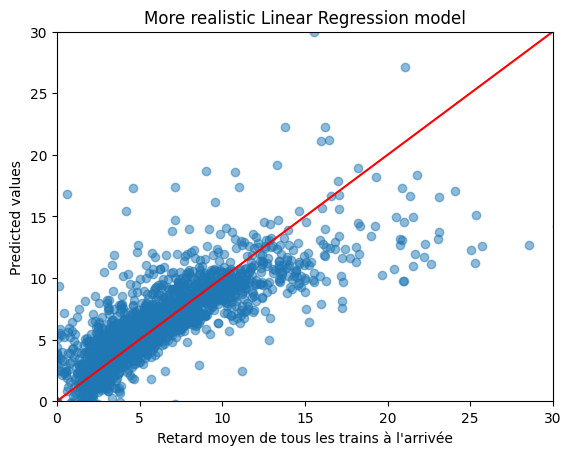

In [102]:
import matplotlib.pyplot as plt

#Compare the model to the actual values, if it is good then it should be close to match the diagonal line

plt.scatter(y_test, y_predict, alpha=0.5)
plt.xlim(0,30)
plt.ylim(0,30)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color = "red")
plt.xlabel("Retard moyen de tous les trains à l'arrivée")
plt.ylabel("Predicted values")
plt.title("More realistic Linear Regression model")
plt.show()